# AI-Based Student Performance Risk Predictor — ANN Training Notebook
Multi-class classification (Low / Medium / High) with a feed-forward ANN in Keras/TensorFlow.
This notebook covers Steps 1–8 of the project brief: data understanding, preprocessing, baseline,
ANN design, training, forward/backward-propagation walkthrough, evaluation and model saving.

In [1]:
import os, json, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, tensorflow as tf, keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
DATA, MODELS, REPORTS = "../data/student_data.csv", "../models", "../reports"
os.makedirs(MODELS, exist_ok=True); os.makedirs(REPORTS, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## Step 1 — Data Understanding

In [2]:
df = pd.read_csv(DATA)
print("Shape:", df.shape)
df.head()

Shape: (15000, 12)


,student_id,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects,performance_category
0,STU21500,24,73.8,7.9,58.3,100.0,55.6,4.7,4.9,5.0,0,Low
1,STU16476,19,58.1,3.9,61.5,100.0,55.5,8.8,5.3,0.0,1,Low
2,STU23168,18,77.5,24.5,86.2,66.9,69.3,8.3,6.6,7.1,0,High
3,STU10863,17,76.1,17.1,78.8,75.7,62.5,8.4,8.0,7.0,1,High
4,STU15971,22,86.3,4.6,76.2,79.6,72.6,5.5,6.4,2.0,0,Low


In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum(), "| Duplicate student_id:", df.student_id.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      15000 non-null  str    
 1   age                             15000 non-null  int64  
 2   attendance_pct                  15000 non-null  float64
 3   study_hours_per_week            15000 non-null  float64
 4   previous_score                  15000 non-null  float64
 5   assignment_completion_pct       15000 non-null  float64
 6   internal_assessment_score       15000 non-null  float64
 7   participation_score             15000 non-null  float64
 8   sleep_hours_per_day             15000 non-null  float64
 9   extracurricular_hours_per_week  15000 non-null  float64
 10  failed_subjects                 15000 non-null  int64  
 11  performance_category            15000 non-null  str    
dtypes: float64(8), int64(2), str(2)
memory usag

In [4]:
TARGET = "performance_category"
FEATURES = [c for c in df.columns if c not in ("student_id", TARGET)]
print("Input features (%d):" % len(FEATURES), FEATURES)
print("Target:", TARGET)
df[FEATURES].describe().T.round(2)

Input features (10): ['age', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'assignment_completion_pct', 'internal_assessment_score', 'participation_score', 'sleep_hours_per_day', 'extracurricular_hours_per_week', 'failed_subjects']
Target: performance_category


,count,mean,std,min,25%,50%,75%,max
age,15000.0,20.47,2.28,17.0,18.0,20.0,22.0,24.0
attendance_pct,15000.0,77.94,11.67,45.0,70.0,77.9,86.1,100.0
study_hours_per_week,15000.0,15.17,6.84,2.0,10.3,15.1,19.8,40.0
previous_score,15000.0,66.65,14.74,25.0,56.8,66.6,76.6,100.0
assignment_completion_pct,15000.0,75.35,15.89,20.0,64.4,75.9,87.5,100.0
internal_assessment_score,15000.0,64.83,15.85,20.0,54.1,64.7,75.8,100.0
participation_score,15000.0,6.15,1.95,1.0,4.8,6.2,7.5,10.0
sleep_hours_per_day,15000.0,6.79,1.10,4.0,6.1,6.8,7.5,10.0
extracurricular_hours_per_week,15000.0,5.12,3.29,0.0,2.6,5.0,7.4,18.0
failed_subjects,15000.0,0.80,0.90,0.0,0.0,1.0,1.0,5.0


performance_category
Low       4950
Medium    5100
High      4950
Name: count, dtype: int64 
 performance_category
Low       33.0
Medium    34.0
High      33.0
Name: count, dtype: float64


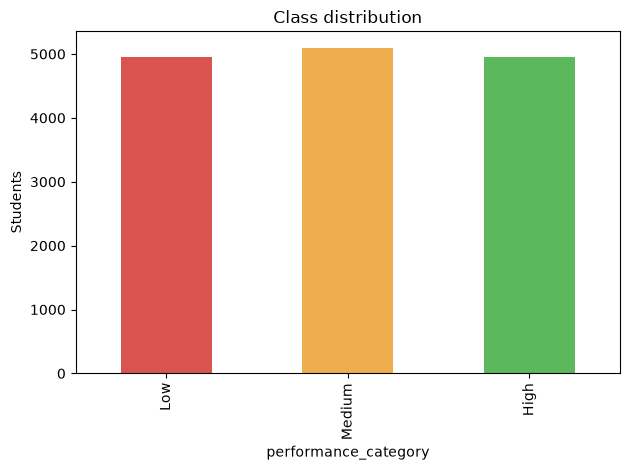

In [5]:
dist = df[TARGET].value_counts().reindex(["Low", "Medium", "High"])
print(dist, "\n", (dist / len(df) * 100).round(2))
ax = dist.plot.bar(color=["#d9534f", "#f0ad4e", "#5cb85c"], title="Class distribution")
ax.set_ylabel("Students"); plt.tight_layout(); plt.savefig(f"{REPORTS}/class_distribution.png", dpi=120); plt.show()

Feature means by class:


performance_category,Low,Medium,High
age,20.52,20.42,20.48
attendance_pct,75.83,78.11,79.87
study_hours_per_week,10.22,15.06,20.24
previous_score,62.61,66.54,70.81
assignment_completion_pct,72.36,75.35,78.34
internal_assessment_score,61.26,64.61,68.62
participation_score,5.59,6.17,6.69
sleep_hours_per_day,6.67,6.80,6.91
extracurricular_hours_per_week,5.41,5.18,4.77
failed_subjects,1.00,0.77,0.62


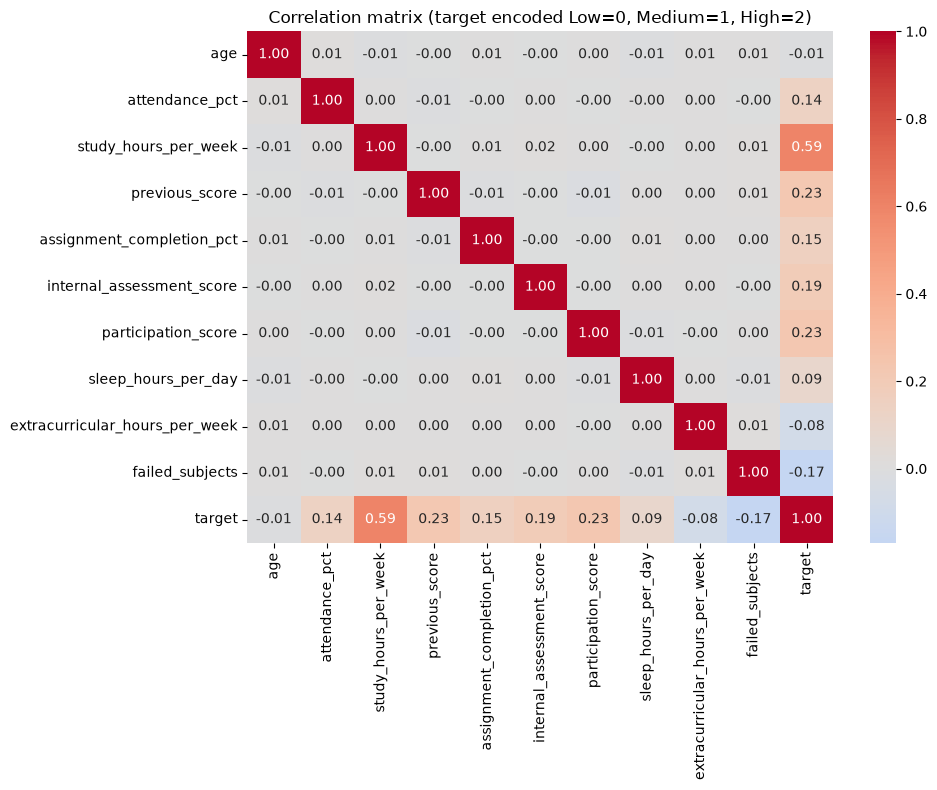

In [6]:
print("Feature means by class:")
display(df.groupby(TARGET)[FEATURES].mean().reindex(["Low", "Medium", "High"]).T.round(2))
corr = df[FEATURES].assign(target=df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})).corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (target encoded Low=0, Medium=1, High=2)"); plt.tight_layout()
plt.savefig(f"{REPORTS}/correlation_heatmap.png", dpi=120); plt.show()

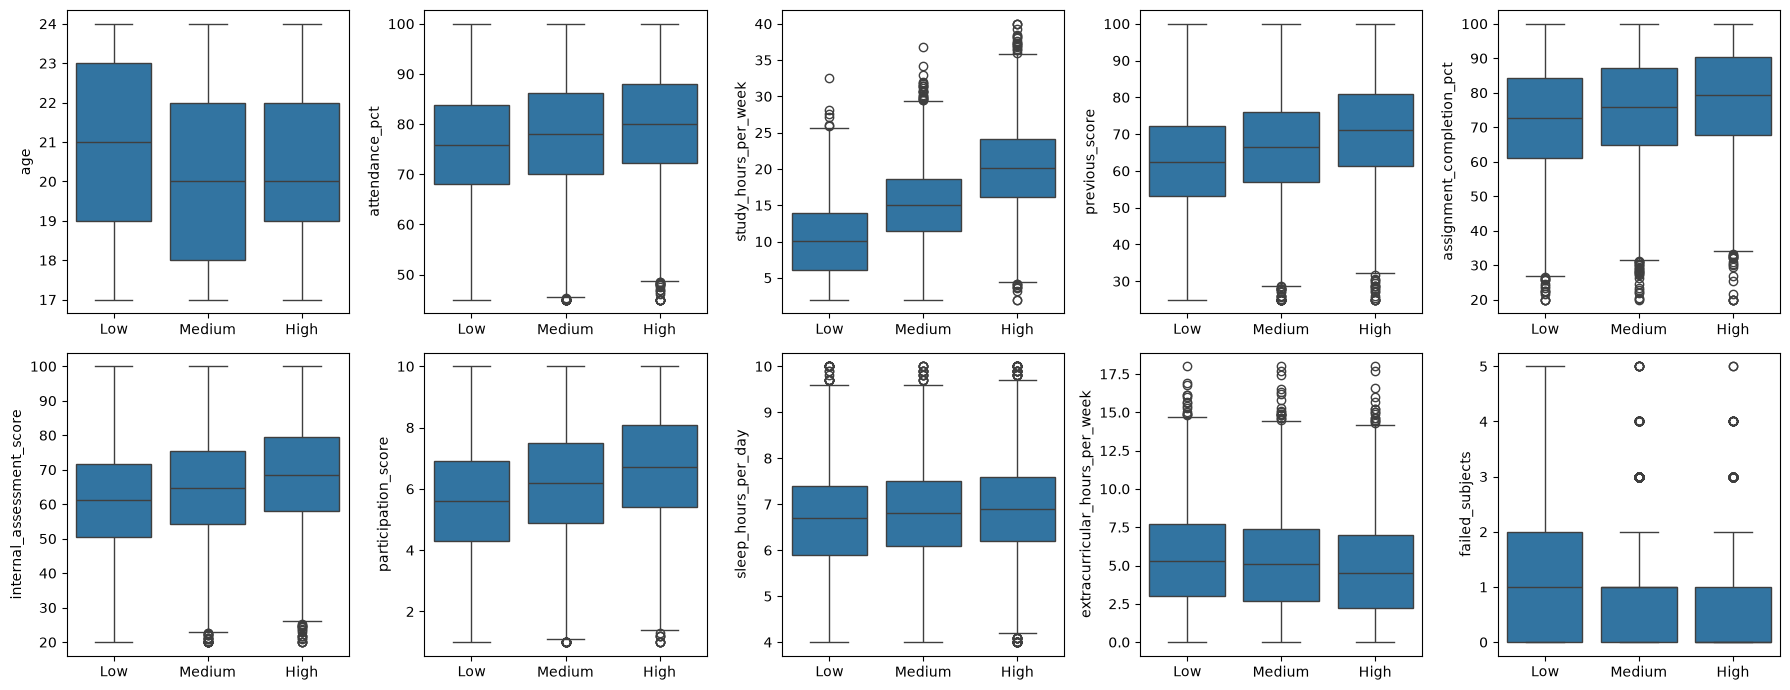

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x=TARGET, y=f, order=["Low", "Medium", "High"], ax=ax); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{REPORTS}/feature_boxplots.png", dpi=110); plt.show()

## Step 2 — Data Preprocessing
* No missing values and no duplicates were found, so no rows are dropped or imputed.
* `student_id` is an identifier with no predictive meaning — dropped.
* Target labels are encoded in their natural order: Low = 0, Medium = 1, High = 2.
* Stratified split: **70 % train / 15 % validation / 15 % test** (class ratios preserved).
* `StandardScaler` (zero mean, unit variance) is **fit on the training set only** and applied to
  validation/test, to avoid leaking test information. The fitted scaler is saved for inference.

In [8]:
CLASSES = ["Low", "Medium", "High"]
X = df[FEATURES]
y = df[TARGET].map({c: i for i, c in enumerate(CLASSES)}).values

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(d) for d in (X_train, X_val, X_test))
joblib.dump(scaler, f"{MODELS}/scaler.joblib")
print("Scaled train means ≈ 0:", X_train_s.mean(0).round(3))
print("Scaled train stds  ≈ 1:", X_train_s.std(0).round(3))

Train: (10500, 10) Val: (2250, 10) Test: (2250, 10)
Scaled train means ≈ 0: [ 0.  0.  0.  0.  0. -0.  0. -0. -0. -0.]
Scaled train stds  ≈ 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Step 3 — Baseline: Logistic Regression
A multinomial Logistic Regression is a linear model and acts as the reference point the ANN has to beat.

In [9]:
def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": p, "recall_macro": r, "f1_macro": f}

baseline = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
base_pred = baseline.predict(X_test_s)
base_metrics = metrics(y_test, base_pred)
print({k: round(v, 4) for k, v in base_metrics.items()})
print(classification_report(y_test, base_pred, target_names=CLASSES, digits=4))

{'accuracy': 0.7067, 'precision_macro': 0.7076, 'recall_macro': 0.708, 'f1_macro': 0.7075}
              precision    recall  f1-score   support

         Low     0.7516    0.7941    0.7723       743
      Medium     0.5803    0.5712    0.5758       765
        High     0.7907    0.7588    0.7744       742

    accuracy                         0.7067      2250
   macro avg     0.7076    0.7080    0.7075      2250
weighted avg     0.7063    0.7067    0.7062      2250



## Step 4 — ANN Design
Feed-forward network: `Input(10) → Dense(ReLU) → Dense(ReLU) → Dense(3, Softmax)`.

* **ReLU** in hidden layers: cheap, non-saturating for positive inputs, lets the network learn non-linear boundaries.
* **Softmax** output with 3 neurons: turns the 3 raw scores into probabilities that sum to 1.
* **Dropout** (light, 0.2) between hidden layers to reduce over-fitting.

The size is chosen empirically: three candidate architectures are compared on the **validation** set
(the test set is untouched until the final evaluation).

In [10]:
def build_ann(hidden=(32, 16), dropout=0.2, lr=1e-3):
    model = keras.Sequential([layers.Input(shape=(len(FEATURES),))])
    for i, units in enumerate(hidden):
        model.add(layers.Dense(units, activation="relu", name=f"hidden_{i+1}"))
        if dropout: model.add(layers.Dropout(dropout))
    model.add(layers.Dense(len(CLASSES), activation="softmax", name="output"))
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

early = lambda: keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
results = {}
for hidden in [(16,), (32, 16), (64, 32), (128, 64, 32)]:
    keras.utils.set_random_seed(SEED)
    m = build_ann(hidden)
    h = m.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=150, batch_size=32,
              callbacks=[early()], verbose=0)
    results[str(hidden)] = {"params": m.count_params(), "epochs": len(h.history["loss"]),
                            "val_loss": min(h.history["val_loss"]),
                            "val_acc": m.evaluate(X_val_s, y_val, verbose=0)[1]}
arch = pd.DataFrame(results).T
arch

,params,epochs,val_loss,val_acc
"(16,)",227.0,30.0,0.664596,0.683111
"(32, 16)",931.0,31.0,0.664733,0.681333
"(64, 32)",2883.0,16.0,0.668194,0.682667
"(128, 64, 32)",11843.0,17.0,0.665398,0.683111


## Step 5 — Training the chosen ANN
* **Loss — sparse categorical cross-entropy:** `-log(p_true_class)`; small when the network assigns high
  probability to the correct class. "Sparse" because labels are integers (0/1/2), not one-hot vectors.
* **Optimizer — Adam (lr = 0.001):** gradient descent with adaptive per-weight step sizes and momentum.
* **Epochs:** up to 150 passes over the training data; **EarlyStopping** (patience 10) stops when
  validation loss stops improving and restores the best weights.
* **Batch size 32:** weights are updated after every 32 samples (≈ 329 updates per epoch).
* **Validation data:** 15 % held out to monitor generalisation and drive early stopping.

In [11]:
CHOSEN = (32, 16)   # see justification in the report: best val accuracy/loss vs. model size
keras.utils.set_random_seed(SEED)
model = build_ann(CHOSEN)
model.summary()
history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=150, batch_size=32,
                    callbacks=[early()], verbose=0)
print("Epochs run:", len(history.history["loss"]))

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 931 (3.64 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 31


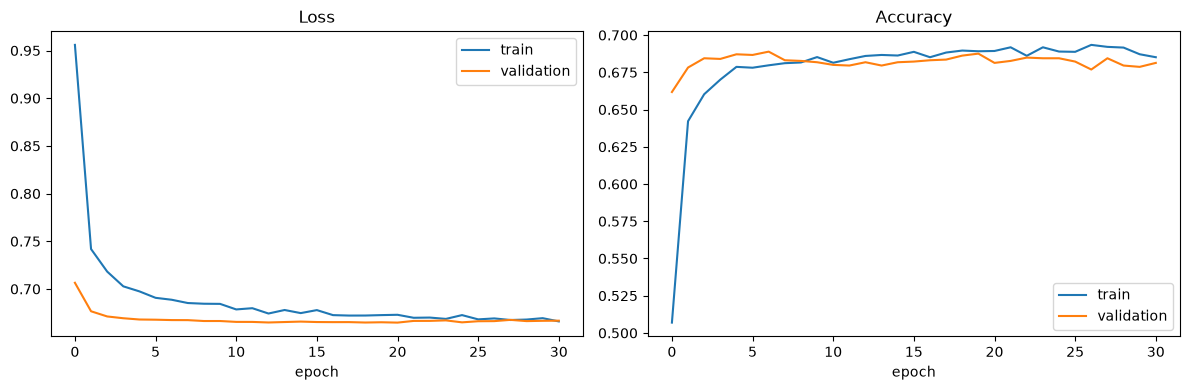

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(history.history["loss"], label="train"); a1.plot(history.history["val_loss"], label="validation")
a1.set_title("Loss"); a1.set_xlabel("epoch"); a1.legend()
a2.plot(history.history["accuracy"], label="train"); a2.plot(history.history["val_accuracy"], label="validation")
a2.set_title("Accuracy"); a2.set_xlabel("epoch"); a2.legend()
plt.tight_layout(); plt.savefig(f"{REPORTS}/training_curves.png", dpi=120); plt.show()

## Step 6 — Forward propagation & backpropagation
**Forward propagation:** each layer computes `z = x·W + b` and then an activation `a = f(z)`.
The cell below reproduces the trained network's prediction for one test student *by hand with NumPy*,
using the learned weights — and shows it matches `model.predict`.
(Dropout is only active during training, so it is skipped at inference.)

**Backpropagation:** after the forward pass the loss compares the predicted probabilities with the true
label. Using the chain rule, the gradient of the loss with respect to every weight and bias is computed
layer by layer from the output back to the input. The optimizer then updates each parameter
`w ← w − η·∂L/∂w` (Adam scales η per weight). Repeating this over many batches is "training".

In [13]:
x = X_test_s[:1]
a = x
dense_layers = [l for l in model.layers if isinstance(l, layers.Dense)]
for layer in dense_layers:
    W, b = layer.get_weights()
    z = a @ W + b
    if layer.name == "output":
        a = np.exp(z - z.max()) / np.exp(z - z.max()).sum()          # softmax
        print(f"{layer.name:9s} z = {z.round(3)}  -> softmax = {a.round(4)}")
    else:
        a = np.maximum(0, z)                                          # ReLU
        print(f"{layer.name:9s} W{W.shape} b{b.shape}  active neurons: {(a > 0).sum()}/{a.size}")
print("Manual forward pass :", a.round(4))
print("model.predict       :", model.predict(x, verbose=0).round(4))
print("True class:", CLASSES[y_test[0]], "| Predicted:", CLASSES[a.argmax()])

hidden_1  W(10, 32) b(32,)  active neurons: 14/32
hidden_2  W(32, 16) b(16,)  active neurons: 6/16
output    z = [[-3.423  0.421  1.453]]  -> softmax = [[0.0056 0.2612 0.7332]]
Manual forward pass : [[0.0056 0.2612 0.7332]]
model.predict       : [[0.0056 0.2612 0.7332]]
True class: High | Predicted: High


In [14]:
# One manual gradient step on a single batch, to make backpropagation concrete
demo = keras.models.clone_model(model); demo.set_weights(model.get_weights())
loss_fn, opt = keras.losses.SparseCategoricalCrossentropy(), keras.optimizers.SGD(0.1)
xb, yb = tf.constant(X_train_s[:32], tf.float32), tf.constant(y_train[:32])
with tf.GradientTape() as tape:
    loss_before = loss_fn(yb, demo(xb, training=False))
grads = tape.gradient(loss_before, demo.trainable_variables)
opt.apply_gradients(zip(grads, demo.trainable_variables))
loss_after = loss_fn(yb, demo(xb, training=False))
for v, g in zip(demo.trainable_variables, grads):
    print(f"{v.path:28s} grad shape {tuple(g.shape)}  mean |grad| = {float(tf.reduce_mean(tf.abs(g))):.5f}")
print(f"Batch loss before update: {float(loss_before):.4f}  after one SGD step: {float(loss_after):.4f}")

sequential_4/hidden_1/kernel grad shape (10, 32)  mean |grad| = 0.01284
sequential_4/hidden_1/bias   grad shape (32,)  mean |grad| = 0.01287
sequential_4/hidden_2/kernel grad shape (32, 16)  mean |grad| = 0.00410
sequential_4/hidden_2/bias   grad shape (16,)  mean |grad| = 0.01791
sequential_4/output/kernel   grad shape (16, 3)  mean |grad| = 0.02619
sequential_4/output/bias     grad shape (3,)  mean |grad| = 0.05611
Batch loss before update: 0.6617  after one SGD step: 0.6404


## Step 7 — Evaluation on unseen test data

In [15]:
proba = model.predict(X_test_s, verbose=0)
ann_pred = proba.argmax(1)
ann_metrics = metrics(y_test, ann_pred)
print(classification_report(y_test, ann_pred, target_names=CLASSES, digits=4))
comparison = pd.DataFrame({"Logistic Regression (baseline)": base_metrics, "ANN": ann_metrics}).T.round(4)
comparison

              precision    recall  f1-score   support

         Low     0.7542    0.7847    0.7691       743
      Medium     0.5673    0.5895    0.5782       765
        High     0.7977    0.7332    0.7640       742

    accuracy                         0.7013      2250
   macro avg     0.7064    0.7025    0.7038      2250
weighted avg     0.7050    0.7013    0.7025      2250


,accuracy,precision_macro,recall_macro,f1_macro
Logistic Regression (baseline),0.7067,0.7076,0.7080,0.7075
ANN,0.7013,0.7064,0.7025,0.7038


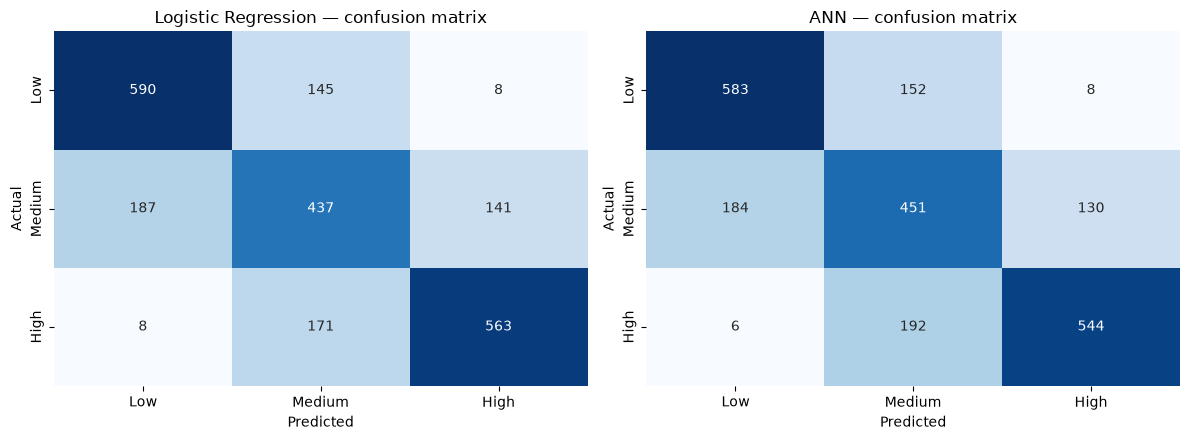

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, [("Logistic Regression", base_pred), ("ANN", ann_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(f"{name} — confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{REPORTS}/confusion_matrices.png", dpi=120); plt.show()

In [17]:
p, r, f, s = precision_recall_fscore_support(y_test, ann_pred)
summary = {
    "dataset": {"rows": len(df), "features": FEATURES, "target": TARGET,
                "class_counts": dist.to_dict(), "split": {"train": len(y_train), "val": len(y_val), "test": len(y_test)}},
    "architecture_search": arch.reset_index(names="hidden").to_dict("records"),
    "chosen_architecture": list(CHOSEN), "params": model.count_params(),
    "epochs_run": len(history.history["loss"]),
    "baseline": base_metrics, "ann": ann_metrics,
    "ann_per_class": {c: {"precision": p[i], "recall": r[i], "f1": f[i], "support": int(s[i])} for i, c in enumerate(CLASSES)},
    "confusion_matrix_ann": confusion_matrix(y_test, ann_pred).tolist(),
    "confusion_matrix_baseline": confusion_matrix(y_test, base_pred).tolist(),
    "mean_confidence_correct": float(proba.max(1)[ann_pred == y_test].mean()),
    "mean_confidence_wrong": float(proba.max(1)[ann_pred != y_test].mean()),
    "adjacent_errors_share": float((np.abs(ann_pred - y_test)[ann_pred != y_test] == 1).mean()),
}
json.dump(summary, open(f"{REPORTS}/metrics.json", "w"), indent=2, default=float)
print(json.dumps({k: summary[k] for k in ("baseline", "ann", "mean_confidence_correct",
                                          "mean_confidence_wrong", "adjacent_errors_share")}, indent=2, default=float))

{
  "baseline": {
    "accuracy": 0.7066666666666667,
    "precision_macro": 0.7075559930970394,
    "recall_macro": 0.7080266665977474,
    "f1_macro": 0.7074747634784219
  },
  "ann": {
    "accuracy": 0.7013333333333334,
    "precision_macro": 0.7063846516253882,
    "recall_macro": 0.702450973081333,
    "f1_macro": 0.7037931198747659
  },
  "mean_confidence_correct": 0.7376081347465515,
  "mean_confidence_wrong": 0.593658983707428,
  "adjacent_errors_share": 0.9791666666666666
}


## Step 8 — Save the trained model and reload it for inference

In [18]:
model.save(f"{MODELS}/student_performance.keras")
reloaded = keras.models.load_model(f"{MODELS}/student_performance.keras")
same = np.allclose(reloaded.predict(X_test_s, verbose=0), proba, atol=1e-6)
print("Saved files:", os.listdir(MODELS), "| reloaded model gives identical predictions:", same)

# Inference exactly as app.py / api.py do it: raw values -> saved scaler -> saved model
student = pd.DataFrame([{"age": 20, "attendance_pct": 82, "study_hours_per_week": 6.5, "previous_score": 71,
                         "assignment_completion_pct": 80, "internal_assessment_score": 68,
                         "participation_score": 7, "sleep_hours_per_day": 7, "extracurricular_hours_per_week": 4,
                         "failed_subjects": 0}])[FEATURES]
pr = reloaded.predict(joblib.load(f"{MODELS}/scaler.joblib").transform(student), verbose=0)[0]
print("Predicted:", CLASSES[pr.argmax()], f"({pr.max():.1%})", dict(zip(CLASSES, pr.round(4))))

Saved files: ['scaler.joblib', 'student_performance.keras'] | reloaded model gives identical predictions: True
Predicted: Medium (53.3%) {'Low': np.float32(0.3564), 'Medium': np.float32(0.5327), 'High': np.float32(0.1108)}


## Steps 9–10
* `app.py` — Streamlit form → prediction + probabilities (`streamlit run app.py`).
* `api.py` — FastAPI `POST /predict` returning JSON (`uvicorn api:app`).
Both load the saved `models/student_performance.keras` and `models/scaler.joblib` via `predictor.py`.